# Chapter 8 — Tree-Based Algorithms and Ensemble Methods

**Book:** *scikit-learn Cookbook, Third Edition* — John Sukup (2025), Chapter 8.

This notebook studies the methods presented in the chapter through runnable Python examples, brief explanations of the underlying ideas, model diagnostics and interpretations of the outputs. Explanatory text is original; code samples are book-aligned demonstrations rather than a verbatim transcript of every recipe.

Run the cells in order in Google Colab.

In [1]:
import sklearn, numpy as np
print("scikit-learn version:", sklearn.__version__)

scikit-learn version: 1.6.1


## 1. Decision tree classification

A decision tree learns recursive feature thresholds. Its rules are easy to inspect, although an unrestricted tree can overfit.

In [2]:
from sklearn.datasets import load_wine
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, export_text
X,y=load_wine(return_X_y=True)
A,B,c,d=train_test_split(X,y,test_size=.3,random_state=42,stratify=y)
tree=DecisionTreeClassifier(max_depth=3,random_state=42).fit(A,c)
print('Train accuracy:',round(tree.score(A,c),3))
print('Test accuracy:',round(tree.score(B,d),3))
print(export_text(tree,feature_names=list(load_wine().feature_names),max_depth=2))

Train accuracy: 0.992
Test accuracy: 0.963
|--- color_intensity <= 3.82
|   |--- ash <= 3.00
|   |   |--- od280/od315_of_diluted_wines <= 3.73
|   |   |   |--- class: 1
|   |   |--- od280/od315_of_diluted_wines >  3.73
|   |   |   |--- class: 0
|   |--- ash >  3.00
|   |   |--- class: 0
|--- color_intensity >  3.82
|   |--- flavanoids <= 1.58
|   |   |--- alcalinity_of_ash <= 17.65
|   |   |   |--- class: 1
|   |   |--- alcalinity_of_ash >  17.65
|   |   |   |--- class: 2
|   |--- flavanoids >  1.58
|   |   |--- proline <= 724.50
|   |   |   |--- class: 1
|   |   |--- proline >  724.50
|   |   |   |--- class: 0



**Interpretation**

The printed rules make the chosen splits visible. Comparing train and test accuracy gives a first indication of whether the tree has become overly specialized.

## 2. Tree depth and pruning

Depth limits and cost-complexity pruning reduce the complexity of a decision tree. Simpler trees can have better test performance when data are limited.

In [3]:
for depth in [1,2,3,None]:
    m=DecisionTreeClassifier(max_depth=depth,random_state=42).fit(A,c)
    print('depth',depth,'train',round(m.score(A,c),3),'test',round(m.score(B,d),3),'leaves',m.get_n_leaves())

depth 1 train 0.661 test 0.611 leaves 2
depth 2 train 0.935 test 0.889 leaves 4
depth 3 train 0.992 test 0.963 leaves 7
depth None train 1.0 test 0.963 leaves 8


**Interpretation**

Deeper trees often fit the training set more closely, but the held-out score need not improve. Leaf count provides another view of model complexity.

## 3. Random forests and bagging

A random forest averages many trees built from varied bootstrap samples and feature subsets. Combining diverse models can lower variance.

In [4]:
from sklearn.ensemble import RandomForestClassifier
forest=RandomForestClassifier(n_estimators=150,random_state=42,oob_score=True).fit(A,c)
print('Forest test accuracy:',round(forest.score(B,d),3))
print('OOB score:',round(forest.oob_score_,3))

Forest test accuracy: 1.0
OOB score: 0.976


**Interpretation**

Out-of-bag observations provide an internal estimate without a separate validation split. It should be interpreted alongside the independent held-out test result.

## 4. Feature importance

Tree ensembles estimate importance from the total impurity reduction associated with splits. These values are useful for exploration but can be biased toward certain feature types.

In [5]:
import numpy as np
names=load_wine().feature_names
idx=np.argsort(forest.feature_importances_)[::-1][:6]
for j in idx:
    print(f'{names[j]:<24} {forest.feature_importances_[j]:.3f}')

flavanoids               0.166
color_intensity          0.166
alcohol                  0.159
proline                  0.127
hue                      0.099
od280/od315_of_diluted_wines 0.090


**Interpretation**

The highest-ranked features contribute substantially to the forest’s splitting decisions. These are model-specific associations, not proof of causal influence.

## 5. Gradient boosting

Gradient boosting builds trees sequentially, each improving predictions relative to the current ensemble. Learning rate and estimator count jointly control model complexity.

In [6]:
from sklearn.ensemble import GradientBoostingClassifier
for rate in [.03,.1,.3]:
    gb=GradientBoostingClassifier(n_estimators=100,learning_rate=rate,max_depth=2,random_state=42).fit(A,c)
    print('learning rate',rate,'test accuracy',round(gb.score(B,d),3))

learning rate 0.03 test accuracy 0.963
learning rate 0.1 test accuracy 0.963
learning rate 0.3 test accuracy 0.981


**Interpretation**

A smaller learning rate makes each stage’s contribution more cautious. The best value is data-dependent, and the test scores show why trying a few settings can be useful.

## 6. Ensemble comparison with cross-validation

Single trees, random forests, and boosting represent different bias-variance trade-offs. Cross-validation supports a more robust comparison.

In [7]:
from sklearn.model_selection import cross_val_score
models={'Tree':DecisionTreeClassifier(max_depth=3,random_state=0),'Forest':RandomForestClassifier(n_estimators=100,random_state=0),'Boosting':GradientBoostingClassifier(random_state=0)}
for name,est in models.items():
    s=cross_val_score(est,X,y,cv=5)
    print(name,'CV accuracy',round(s.mean(),3),'std',round(s.std(),3))

Tree CV accuracy 0.893 std 0.066
Forest CV accuracy 0.983 std 0.022
Boosting CV accuracy 0.939 std 0.032


**Interpretation**

The mean score summarizes performance over folds; standard deviation reveals variability between them. The most complex ensemble does not necessarily win by a meaningful margin.

## 7. Understanding decision tree split criteria

Classification trees can choose splits using Gini impurity or entropy. Both reward splits that produce purer child groups, although they quantify impurity differently.

In [8]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score
for criterion in ['gini','entropy','log_loss']:
    t=DecisionTreeClassifier(max_depth=4,criterion=criterion,random_state=42).fit(A,c)
    print(f'{criterion:8} depth={t.get_depth()} leaves={t.get_n_leaves()} test accuracy={accuracy_score(d,t.predict(B)):.3f}')

gini     depth=4 leaves=8 test accuracy=0.963
entropy  depth=3 leaves=6 test accuracy=0.907
log_loss depth=3 leaves=6 test accuracy=0.907


**Interpretation**

The algorithms may produce similar or different trees depending on the data. The comparison shows that the split criterion influences the model structure, but test-set performance remains the relevant measure for deciding whether those changes help.

## 8. Cost-complexity pruning path

A tree grown without restrictions can overfit. Minimal cost-complexity pruning gives a sequence of candidate subtree complexities. Alpha controls the penalty for adding leaves.

First pruning candidates (alpha, leaves, test accuracy):
(0.0, 8.0, 0.963)
(0.0138, 7.0, 0.963)
(0.0154, 5.0, 0.9444)
(0.0157, 4.0, 0.963)
(0.07, 3.0, 0.8889)


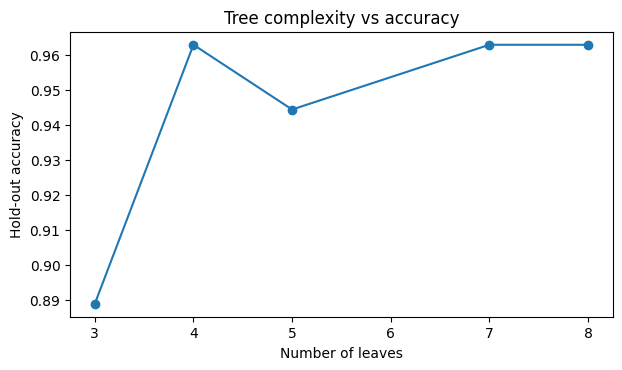

In [9]:
import matplotlib.pyplot as plt
full=DecisionTreeClassifier(random_state=42).fit(A,c)
path=full.cost_complexity_pruning_path(A,c)
alphas=np.unique(path.ccp_alphas[:-1])
pruned=[]
for alpha in alphas:
    t=DecisionTreeClassifier(random_state=42,ccp_alpha=float(alpha)).fit(A,c)
    pruned.append((alpha,t.get_n_leaves(),t.score(B,d)))
print('First pruning candidates (alpha, leaves, test accuracy):')
for item in pruned[:7]:print(tuple(round(float(z),4) for z in item))
fig,ax=plt.subplots(figsize=(7,3.7));ax.plot([v[1] for v in pruned],[v[2] for v in pruned],'o-')
ax.set(xlabel='Number of leaves',ylabel='Hold-out accuracy',title='Tree complexity vs accuracy');plt.show()

**Interpretation**

A smaller tree uses fewer terminal decision regions and is easier to interpret. The plot shows whether additional leaves actually help on the held-out data. Picking the best alpha should ideally be done by cross-validation rather than repeated inspection of the test set.

## 9. Bagging versus a single tree

Bagging trains multiple models on bootstrap samples, then aggregates their predictions. This can reduce the variance of unstable estimators such as fully grown decision trees.

In [10]:
from sklearn.ensemble import BaggingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=7)
tree=DecisionTreeClassifier(random_state=42)
bag=BaggingClassifier(estimator=DecisionTreeClassifier(random_state=42),n_estimators=60,random_state=42,n_jobs=-1)
for name,model in [('Single tree',tree),('Bagging',bag)]:
    s=cross_val_score(model,X,y,cv=cv,scoring='accuracy')
    print(f'{name}: CV accuracy={s.mean():.3f} +/- {s.std():.3f}')

Single tree: CV accuracy=0.904 +/- 0.034
Bagging: CV accuracy=0.955 +/- 0.023


**Interpretation**

The comparison uses the same folds for both methods. Bagging may produce a more stable score by averaging predictions, but the improvement depends on whether the individual trees make sufficiently different errors.

## 10. Learning curves for ensemble size

A forest generally becomes more stable as the number of trees increases, but computational cost also rises. An experiment over several ensemble sizes makes the diminishing returns visible.

Trees and test accuracy: [(5, 0.963), (15, 0.981), (40, 1.0), (100, 1.0), (180, 1.0)]


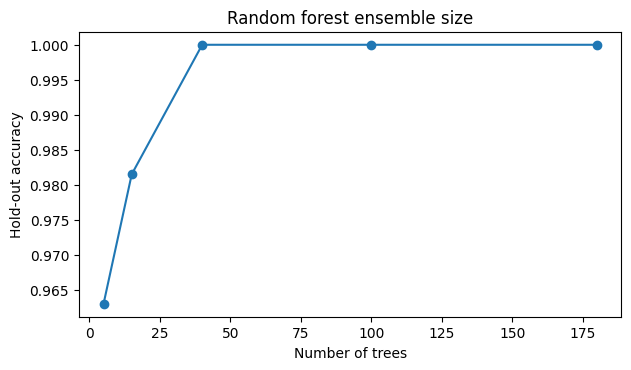

In [11]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
sizes=[5,15,40,100,180]
results=[]
for count in sizes:
    rf=RandomForestClassifier(n_estimators=count,random_state=42,n_jobs=-1).fit(A,c)
    results.append(accuracy_score(d,rf.predict(B)))
print('Trees and test accuracy:',list(zip(sizes,[round(v,3) for v in results])))
fig,ax=plt.subplots(figsize=(7,3.7));ax.plot(sizes,results,marker='o');ax.set(xlabel='Number of trees',ylabel='Hold-out accuracy',title='Random forest ensemble size');plt.show()

**Interpretation**

The accuracy does not have to increase monotonically for every finite test set. Once the curve stabilizes, adding many more trees may cost more time without meaningful improvement.

## 11. Decision tree visualization and leaf predictions

Decision trees divide feature space through a sequence of if/else rules. A plot of the learned branches helps connect the model predictions with the feature thresholds used to reach each leaf.

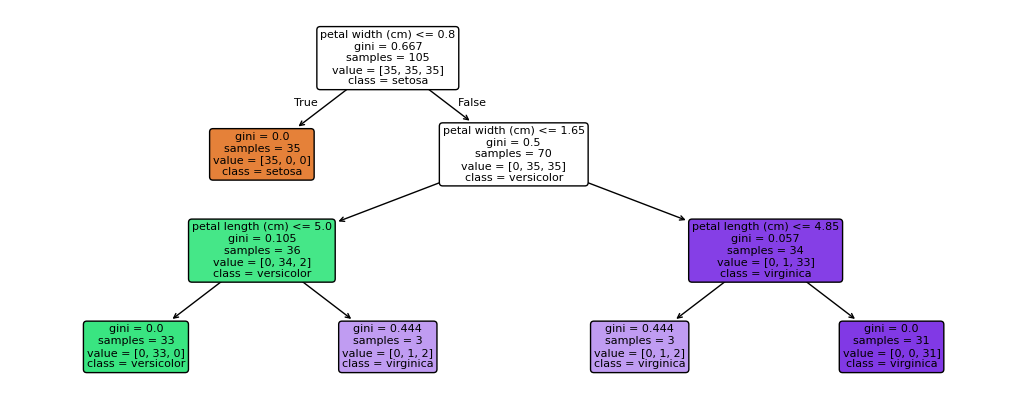

Leaf count: 5 test accuracy: 0.956


In [12]:
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier,plot_tree
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
iris=load_iris()
Aa,Bb,cc,dd=train_test_split(iris.data,iris.target,test_size=.3,stratify=iris.target,random_state=18)
tree_v=DecisionTreeClassifier(max_depth=3,random_state=18).fit(Aa,cc)
fig,ax=plt.subplots(figsize=(13,5))
plot_tree(tree_v,feature_names=list(iris.feature_names),class_names=list(iris.target_names),filled=True,rounded=True,fontsize=8,ax=ax)
plt.show()
print('Leaf count:',tree_v.get_n_leaves(),'test accuracy:',round(tree_v.score(Bb,dd),3))

**Interpretation**

Each split tests one numerical threshold and directs observations toward different leaves. The leaf labels and proportions explain the decisions, but a small tree may miss patterns that a more flexible model captures.

## 12. Depth and minimum leaf size

The max_depth and min_samples_leaf parameters jointly control tree complexity. Limiting depth reduces the number of successive splits, while increasing minimum leaf size prevents decisions from relying on very few samples.

In [13]:
for depth in [2,4,8,None]:
    for leaf in [1,5,12]:
        t=DecisionTreeClassifier(max_depth=depth,min_samples_leaf=leaf,random_state=18).fit(Aa,cc)
        print(f'depth={str(depth):>4} leaf={leaf:>2} leaves={t.get_n_leaves():>2} train={t.score(Aa,cc):.3f} test={t.score(Bb,dd):.3f}')

depth=   2 leaf= 1 leaves= 3 train=0.971 test=0.933
depth=   2 leaf= 5 leaves= 3 train=0.971 test=0.933
depth=   2 leaf=12 leaves= 3 train=0.971 test=0.933
depth=   4 leaf= 1 leaves= 7 train=1.000 test=0.956
depth=   4 leaf= 5 leaves= 5 train=0.971 test=0.933
depth=   4 leaf=12 leaves= 5 train=0.971 test=0.933
depth=   8 leaf= 1 leaves= 7 train=1.000 test=0.956
depth=   8 leaf= 5 leaves= 5 train=0.971 test=0.933
depth=   8 leaf=12 leaves= 5 train=0.971 test=0.933
depth=None leaf= 1 leaves= 7 train=1.000 test=0.956
depth=None leaf= 5 leaves= 5 train=0.971 test=0.933
depth=None leaf=12 leaves= 5 train=0.971 test=0.933


**Interpretation**

Large trees usually fit the training set more closely, but they do not always improve test performance. The parameter grid shows whether reducing complexity produces a more stable generalization pattern.

## 13. Random forest out-of-bag estimate

Bootstrap sampling means each tree is trained on a sample containing repeated observations, leaving some records out. These out-of-bag observations can be used to approximate validation performance without holding out a separate dataset.

In [14]:
from sklearn.ensemble import RandomForestClassifier
rf_oob=RandomForestClassifier(n_estimators=160,oob_score=True,bootstrap=True,random_state=18,n_jobs=-1).fit(Aa,cc)
print('OOB accuracy:',round(rf_oob.oob_score_,3))
print('Held-out accuracy:',round(rf_oob.score(Bb,dd),3))

OOB accuracy: 0.943
Held-out accuracy: 0.933


**Interpretation**

The OOB score offers an internal check derived from unused bootstrap observations. It may be close to or different from the test result because the two estimates use different sets of predictions.

## 14. Random feature subsets in forests

Random forests introduce diversity by giving each split access to only some features. The max_features setting changes how strongly the trees resemble one another and can affect ensemble accuracy.

In [15]:
for subset in ['sqrt','log2',None]:
    f=RandomForestClassifier(n_estimators=100,max_features=subset,random_state=18,n_jobs=-1).fit(Aa,cc)
    print(f'max_features={str(subset):>5} train={f.score(Aa,cc):.3f} test={f.score(Bb,dd):.3f}')

max_features= sqrt train=1.000 test=0.933
max_features= log2 train=1.000 test=0.933
max_features= None train=1.000 test=0.956


**Interpretation**

Reducing feature availability can lower correlations among the individual trees. However, too few candidate features at each split can also weaken individual trees; the best setting depends on the data.

## 15. Permutation importance on held-out data

Impurity-based feature importance can be biased toward features with many possible split points. Permutation importance provides a model-agnostic alternative by measuring how much performance deteriorates when a feature is shuffled.

In [16]:
from sklearn.inspection import permutation_importance
pi=permutation_importance(rf_oob,Bb,dd,n_repeats=8,random_state=18,n_jobs=-1)
for i in np.argsort(pi.importances_mean)[::-1]:
    print(f'{iris.feature_names[i]:25s} mean drop={pi.importances_mean[i]:.3f}')

petal length (cm)         mean drop=0.250
petal width (cm)          mean drop=0.178
sepal width (cm)          mean drop=-0.006
sepal length (cm)         mean drop=-0.017


**Interpretation**

A larger positive decrease indicates that the fitted model relies more heavily on that feature for this test set. With correlated inputs, permutation can underestimate the importance of an individual feature because substitutes remain available.

## 16. Gradient boosting learning rate and stages

Gradient boosting grows trees sequentially so each new learner corrects errors in the current ensemble. Smaller learning rates generally require more boosting stages to achieve comparable fit.

In [17]:
from sklearn.ensemble import GradientBoostingClassifier
for rate,estimators in [(0.02,40),(.05,100),(.1,100),(.2,100)]:
    g=GradientBoostingClassifier(learning_rate=rate,n_estimators=estimators,max_depth=2,random_state=18).fit(Aa,cc)
    print(f'rate={rate:.2f}, trees={estimators}, train={g.score(Aa,cc):.3f}, test={g.score(Bb,dd):.3f}')

rate=0.02, trees=40, train=0.981, test=0.956
rate=0.05, trees=100, train=1.000, test=0.933
rate=0.10, trees=100, train=1.000, test=0.933
rate=0.20, trees=100, train=1.000, test=0.933


**Interpretation**

Lower learning rates yield smaller updates at every stage. A small rate with too few trees may underfit, while aggressive updates may overfit; results on the held-out data clarify the trade-off.

## 17. Boosting staged validation accuracy

A boosting model can be evaluated after successive stages. Looking at these intermediate predictions can show whether more trees are still improving the held-out score or if performance has leveled off.

Test accuracy by stage: {1: 0.956, 5: 0.956, 10: 0.956, 25: 0.956, 50: 0.956, 75: 0.956, 100: 0.933}


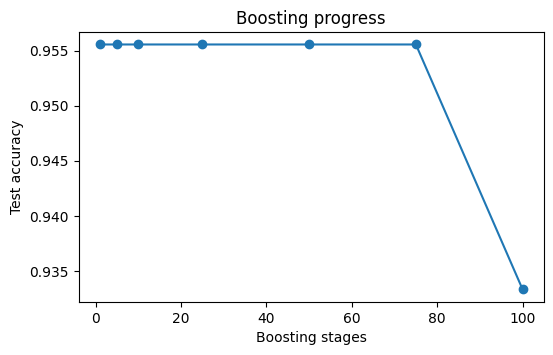

In [18]:
from sklearn.metrics import accuracy_score
gbm=GradientBoostingClassifier(n_estimators=100,learning_rate=.08,random_state=18).fit(Aa,cc)
stages=[1,5,10,25,50,75,100]
accuracies={i:accuracy_score(dd,pred) for i,pred in enumerate(gbm.staged_predict(Bb),1) if i in stages}
print('Test accuracy by stage:',{k:round(v,3) for k,v in accuracies.items()})
plt.figure(figsize=(6,3.5));plt.plot(list(accuracies),list(accuracies.values()),marker='o');plt.xlabel('Boosting stages');plt.ylabel('Test accuracy');plt.title('Boosting progress');plt.show()

**Interpretation**

The accuracy can improve quickly and later stabilize or fluctuate. Choosing the stage number using a designated validation set rather than the final test set avoids repeated test-set tuning.

## 18. Cross-validation for tree hyperparameters

A single split is not enough to reliably select tree depth or minimum leaf size. Grid search combines cross-validation with the model’s hyperparameter space to identify a more defensible configuration.

In [19]:
from sklearn.model_selection import GridSearchCV
from sklearn.model_selection import StratifiedKFold
search=GridSearchCV(DecisionTreeClassifier(random_state=18),{'max_depth':[2,3,4,5,None],'min_samples_leaf':[1,3,8]},cv=StratifiedKFold(5,shuffle=True,random_state=18)).fit(Aa,cc)
print('Best parameters:',search.best_params_)
print('Mean CV accuracy:',round(search.best_score_,3))
print('Hold-out accuracy:',round(search.score(Bb,dd),3))

Best parameters: {'max_depth': 3, 'min_samples_leaf': 3}
Mean CV accuracy: 0.962
Hold-out accuracy: 0.956


**Interpretation**

The search balances model complexity against validation accuracy. The test score is calculated after choosing the configuration and therefore gives a separate check of generalization.

## 19. Voting ensembles of different models

A voting ensemble combines several different algorithms rather than many instances of the same learner. Hard voting uses predicted labels; soft voting averages class probabilities when the base estimators support them.

In [20]:
from sklearn.ensemble import VotingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
vote=VotingClassifier(estimators=[('tree',DecisionTreeClassifier(max_depth=4,random_state=18)),('logistic',make_pipeline(StandardScaler(),LogisticRegression(max_iter=2000))),('knn',make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=5)))],voting='soft').fit(Aa,cc)
print('Soft voting accuracy:',round(vote.score(Bb,dd),3))
for name,est in vote.named_estimators_.items():
    print(name,'accuracy:',round(est.score(Bb,dd),3))

Soft voting accuracy: 0.956
tree accuracy: 0.956
logistic accuracy: 0.956
knn accuracy: 0.978


**Interpretation**

Voting benefits depend on the diversity of errors from the constituent models. It does not automatically beat the strongest model; the individual scores help explain whether combining predictions was useful here.

## 20. Stacking classifiers with a meta-learner

Stacking trains a final estimator on predictions produced by base models. Proper implementations use cross-validated base predictions for meta-model training to limit the leakage that would occur if the meta-model learned on overly optimistic in-sample predictions.

In [21]:
from sklearn.ensemble import StackingClassifier
stack=StackingClassifier(estimators=[('tree',DecisionTreeClassifier(max_depth=3,random_state=18)),('forest',RandomForestClassifier(n_estimators=70,random_state=18)),('knn',make_pipeline(StandardScaler(),KNeighborsClassifier(n_neighbors=7)))],final_estimator=LogisticRegression(max_iter=2000),cv=4).fit(Aa,cc)
print('Stacking test accuracy:',round(stack.score(Bb,dd),3))
print('Random forest test accuracy:',round(rf_oob.score(Bb,dd),3))

Stacking test accuracy: 0.956
Random forest test accuracy: 0.933


**Interpretation**

The final accuracy indicates whether using several base predictions helped this particular dataset. Stacking requires extra training and validation work; for small datasets, the increase in complexity may not be justified by a tiny score change.